In [1]:
import pandas as pd
import numpy as np
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.dummy import DummyClassifier

In [3]:
from google.colab import files

uploaded = files.upload()

Saving recommendation_feedback.csv to recommendation_feedback.csv
Saving job_dataset.csv to job_dataset.csv
Saving student_profiles.csv to student_profiles.csv


In [4]:
import pandas as pd

students = pd.read_csv("/content/student_profiles.csv")
jobs = pd.read_csv("/content/job_dataset.csv")
feedback = pd.read_csv("/content/recommendation_feedback.csv")

print("All files loaded successfully!")

All files loaded successfully!


In [5]:
print("STUDENT COLUMNS:")
print(students.columns.tolist())

print("\nJOB COLUMNS:")
print(jobs.columns.tolist())

print("\nFEEDBACK COLUMNS:")
print(feedback.columns.tolist())

STUDENT COLUMNS:
['student_id', 'degree', 'specialization', 'graduation_year', 'technical_skills', 'programming_languages', 'skill_proficiency', 'projects_count', 'project_technologies', 'project_descriptions', 'internship_months', 'work_experience_months', 'certifications', 'preferred_roles', 'preferred_locations', 'preferred_work_mode', 'job_type_preference']

JOB COLUMNS:
['job_id', 'job_title', 'company', 'required_skills', 'preferred_skills', 'min_experience_months', 'max_experience_months', 'required_degree', 'location', 'work_mode', 'job_type', 'job_description']

FEEDBACK COLUMNS:
['student_id', 'job_id', 'recommendation_date', 'match_score', 'admin_approved', 'student_feedback', 'application_status', 'outcome']


In [6]:
# Merge feedback with student profiles
data = feedback.merge(
    students,
    on="student_id",
    how="inner"
)

# Merge the result with job details
data = data.merge(
    jobs,
    on="job_id",
    how="inner"
)

print("Datasets merged successfully!")
print("Total records:", len(data))
print("Total columns:", len(data.columns))

display(data.head())

Datasets merged successfully!
Total records: 1000
Total columns: 35


,student_id,job_id,recommendation_date,match_score,admin_approved,student_feedback,application_status,outcome,degree,specialization,...,company,required_skills,preferred_skills,min_experience_months,max_experience_months,required_degree,location,work_mode,job_type,job_description
0,STU0241,JOB0718,2026-05-24,28.8,NaN,NaN,NaN,NaN,M.Tech,Data Science,...,DataLeaf Analytics,Flask; Git; SQL; Node.js,Spring Boot; Docker; REST APIs,36,60,B.Tech; B.E.; BCA; MCA; M.Tech; B.Sc,Bengaluru,Hybrid,Full-time,DataLeaf Analytics is hiring a API Developer t...
1,STU0572,JOB0860,2026-05-24,70.0,NaN,Not relevant,NaN,NaN,M.Tech,Electronics and Communication,...,Fractal Analytics,Java; PostgreSQL; Git; Docker; Django,Spring Boot; MongoDB; Python,0,12,B.Tech; B.E.; MCA; M.Tech,Remote,Remote,Full-time,Fractal Analytics is hiring a Junior Java Deve...
2,STU0833,JOB0034,2026-05-24,60.1,Yes,Relevant,Rejected,Not selected,B.Tech,Artificial Intelligence and Machine Learning,...,Paytm,Terraform; Ansible; Prometheus,Kubernetes; Git,36,48,B.Tech; B.E.; M.Tech,Hyderabad,Hybrid,Full-time,Paytm is hiring a DevOps Engineer to work on c...
3,STU0487,JOB0825,2026-05-24,80.9,Yes,NaN,Rejected,Not selected,MCA,Computer Applications,...,DataLeaf Analytics,Docker; Django; SQL; Git; REST APIs,Redis; Java,24,36,Any Graduate,Bhubaneswar,Onsite,Full-time,DataLeaf Analytics is hiring a Junior Java Dev...
4,STU0192,JOB0927,2026-05-24,51.5,Yes,Relevant,Shortlisted,NaN,B.Tech,Computer Science,...,Nagarro,SQL; Tableau; NumPy; Pandas,Power BI; R; Python,24,36,B.Tech; B.E.; MCA; M.Tech,Remote,Remote,Full-time,Nagarro is hiring a Junior Data Analyst to wor...


In [7]:
print("Outcome values:")
print(data["outcome"].value_counts(dropna=False))

print("\nApplication status values:")
print(data["application_status"].value_counts(dropna=False))

print("\nStudent feedback values:")
print(data["student_feedback"].value_counts(dropna=False))

Outcome values:
outcome
NaN                   840
Not selected           90
Candidate withdrew     35
Offer accepted         27
Offer declined          8
Name: count, dtype: int64

Application status values:
application_status
NaN                    677
Rejected                90
Applied                 90
Shortlisted             48
Withdrawn               35
Offered                 35
Interview Scheduled     25
Name: count, dtype: int64

Student feedback values:
student_feedback
NaN             627
Relevant        267
Not relevant    106
Name: count, dtype: int64


In [8]:
# Keep only records with student feedback
ml_data = data.dropna(subset=["student_feedback"]).copy()

# Keep only the two valid feedback categories
ml_data = ml_data[
    ml_data["student_feedback"].isin(["Relevant", "Not relevant"])
]

# Check the result
print("Total labeled records:", len(ml_data))

print("\nTarget distribution:")
print(ml_data["student_feedback"].value_counts())

display(ml_data.head())

Total labeled records: 373

Target distribution:
student_feedback
Relevant        267
Not relevant    106
Name: count, dtype: int64


,student_id,job_id,recommendation_date,match_score,admin_approved,student_feedback,application_status,outcome,degree,specialization,...,company,required_skills,preferred_skills,min_experience_months,max_experience_months,required_degree,location,work_mode,job_type,job_description
1,STU0572,JOB0860,2026-05-24,70.0,NaN,Not relevant,NaN,NaN,M.Tech,Electronics and Communication,...,Fractal Analytics,Java; PostgreSQL; Git; Docker; Django,Spring Boot; MongoDB; Python,0,12,B.Tech; B.E.; MCA; M.Tech,Remote,Remote,Full-time,Fractal Analytics is hiring a Junior Java Deve...
2,STU0833,JOB0034,2026-05-24,60.1,Yes,Relevant,Rejected,Not selected,B.Tech,Artificial Intelligence and Machine Learning,...,Paytm,Terraform; Ansible; Prometheus,Kubernetes; Git,36,48,B.Tech; B.E.; M.Tech,Hyderabad,Hybrid,Full-time,Paytm is hiring a DevOps Engineer to work on c...
4,STU0192,JOB0927,2026-05-24,51.5,Yes,Relevant,Shortlisted,NaN,B.Tech,Computer Science,...,Nagarro,SQL; Tableau; NumPy; Pandas,Power BI; R; Python,24,36,B.Tech; B.E.; MCA; M.Tech,Remote,Remote,Full-time,Nagarro is hiring a Junior Data Analyst to wor...
7,STU0073,JOB0278,2026-05-25,18.0,Yes,Relevant,Rejected,Not selected,B.E.,Electronics and Communication,...,BrowserStack,SIEM; Network Security; Cryptography,Linux; Kali Linux,0,6,B.Tech; B.E.; MCA; M.Tech,Bengaluru,Hybrid,Internship,BrowserStack is hiring a Penetration Tester In...
8,STU0243,JOB0086,2026-05-25,21.2,Yes,Relevant,NaN,NaN,M.Tech,Computer Science,...,CRED,Django; Redis; Python,Docker; Spring Boot; Node.js; Flask,12,48,B.Tech; B.E.; MCA; M.Tech,Ahmedabad,Hybrid,Full-time,CRED is hiring a API Developer to work on a fa...


In [9]:
print("Duplicate student-job pairs:")

print(
    ml_data.duplicated(
        subset=["student_id", "job_id"]
    ).sum()
)

Duplicate student-job pairs:
0


In [10]:
# Replace missing values with empty text
text_columns = [
    "degree",
    "specialization",
    "technical_skills",
    "programming_languages",
    "skill_proficiency",
    "project_technologies",
    "project_descriptions",
    "preferred_roles",
    "preferred_locations",
    "preferred_work_mode",
    "job_type_preference",
    "job_title",
    "required_skills",
    "preferred_skills",
    "required_degree",
    "location",
    "work_mode",
    "job_type",
    "job_description"
]

ml_data[text_columns] = ml_data[text_columns].fillna("")

# Combine student and job information
ml_data["combined_text"] = ml_data[text_columns].astype(str).agg(" ".join, axis=1)

# Check the result
print(ml_data["combined_text"].iloc[0])

M.Tech Electronics and Communication Python; REST APIs; MongoDB; Django; Redis; Node.js; Docker; SQL; Flask; Java Python; SQL; Java Python:Intermediate; REST APIs:Intermediate; MongoDB:Beginner; Django:Intermediate Java; Spring Boot; MySQL; Python; Flask; Redis Inventory management REST API; URL shortener service API Developer; Associate Software Engineer; Software Tester Kochi; Bengaluru; Remote Remote Full-time Junior Java Developer Java; PostgreSQL; Git; Docker; Django Spring Boot; MongoDB; Python B.Tech; B.E.; MCA; M.Tech Remote Remote Full-time Fractal Analytics is hiring a Junior Java Developer to work on a fast-growing product team. You will use Java, PostgreSQL, Git to design and ship features. Familiarity with Spring Boot, MongoDB is a plus; freshers are welcome to apply.


In [11]:
ml_data["target"] = ml_data["student_feedback"].map({
    "Not relevant": 0,
    "Relevant": 1
})

print(ml_data[["student_feedback", "target"]].head())

  student_feedback  target
1     Not relevant       0
2         Relevant       1
4         Relevant       1
7         Relevant       1
8         Relevant       1


In [12]:
from sklearn.model_selection import GroupShuffleSplit

# Define input and target
X = ml_data["combined_text"]
y = ml_data["target"]
groups = ml_data["student_id"]

# Split data by student ID
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Training students:", groups.iloc[train_idx].nunique())
print("Testing students:", groups.iloc[test_idx].nunique())

Training records: 298
Testing records: 75
Training students: 248
Testing students: 63


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Create the ML pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        max_features=10000
    )),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("ML model created successfully!")

ML model created successfully!


In [14]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [15]:
y_pred = model.predict(X_test)

print("Predictions completed!")

print("Actual values:")
print(y_test.tolist())

print("\nPredicted values:")
print(y_pred.tolist())

Predictions completed!
Actual values:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1]

Predicted values:
[1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1]


In [16]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Detailed performance report
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not relevant", "Relevant"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

Model Accuracy: 62.67 %

Classification Report:
              precision    recall  f1-score   support

Not relevant       0.25      0.28      0.26        18
    Relevant       0.76      0.74      0.75        57

    accuracy                           0.63        75
   macro avg       0.51      0.51      0.51        75
weighted avg       0.64      0.63      0.63        75


Confusion Matrix:
[[ 5 13]
 [15 42]]


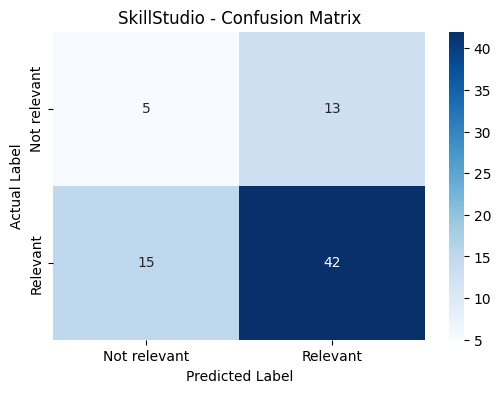

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not relevant", "Relevant"],
    yticklabels=["Not relevant", "Relevant"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SkillStudio - Confusion Matrix")

plt.show()

In [18]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_test)

dummy_accuracy = accuracy_score(y_test, dummy_pred)

print("Dummy Model Accuracy:", round(dummy_accuracy * 100, 2), "%")

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")

Dummy Model Accuracy: 76.0 %
Logistic Regression Accuracy: 62.67 %


In [19]:
import joblib

model_path = "skillstudio_ml_model.joblib"

joblib.dump(model, model_path)

print("Model saved successfully!")

Model saved successfully!


In [20]:
from google.colab import files

files.download("skillstudio_ml_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
new_example = """
B.Tech Computer Science
Python Java SQL
Django Flask
Backend Developer
Required skills Python Django SQL
Preferred skills PostgreSQL Git
Remote Full-time
Develop backend APIs and database applications
"""

# Predict class
prediction = model.predict([new_example])[0]

# Get prediction probabilities
probabilities = model.predict_proba([new_example])[0]

if prediction == 1:
    print("Prediction: Relevant")
else:
    print("Prediction: Not relevant")

print(
    "Probability of Not relevant:",
    round(probabilities[0] * 100, 2), "%"
)

print(
    "Probability of Relevant:",
    round(probabilities[1] * 100, 2), "%"
)

Prediction: Not relevant
Probability of Not relevant: 50.59 %
Probability of Relevant: 49.41 %


In [22]:
tfidf = model.named_steps["tfidf"]

classifier = model.named_steps["classifier"]

feature_names = tfidf.get_feature_names_out()

coefficients = classifier.coef_[0]

# Most important words for Relevant
top_relevant = coefficients.argsort()[-15:][::-1]

print("Words associated with Relevant:")

for index in top_relevant:
    print(feature_names[index], coefficients[index])

# Most important words for Not relevant
top_not_relevant = coefficients.argsort()[:15]

print("\nWords associated with Not relevant:")

for index in top_not_relevant:
    print(feature_names[index], coefficients[index])

Words associated with Relevant:
sql 0.4584017551444171
internship 0.4581175726577695
intern 0.450607572938037
dart 0.44429896482456643
sqlite 0.3963448721322621
deep learning 0.3894886640230981
deep 0.3894886640230981
javascript python 0.37311320294095546
web 0.3720971831126578
data analyst 0.36645892743505354
css 0.35948222529170526
git 0.3544864167032028
mern stack 0.33708937209560375
mern 0.33708937209560375
engineer intern 0.3298796706919958

Words associated with Not relevant:
figma -0.5311293866792928
redux -0.5180725558620224
bash -0.46316304091766564
hybrid time -0.45741152166906707
js python -0.4252050141220141
python spring -0.41373552696594446
iot python -0.390392627363421
hybrid -0.3831158955205526
terraform -0.36501908299701863
boot docker -0.35719223756251434
linux -0.3546011452147814
java -0.34853247910506946
flask postgresql -0.34199599171265377
python postgresql -0.3320746254509258
qa -0.3317604340254848


In [23]:
from sklearn.metrics import classification_report, confusion_matrix

print("LOGISTIC REGRESSION:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not relevant", "Relevant"],
    zero_division=0
))

print("\nDUMMY MODEL:")
print(classification_report(
    y_test,
    dummy_pred,
    target_names=["Not relevant", "Relevant"],
    zero_division=0
))

LOGISTIC REGRESSION:
              precision    recall  f1-score   support

Not relevant       0.25      0.28      0.26        18
    Relevant       0.76      0.74      0.75        57

    accuracy                           0.63        75
   macro avg       0.51      0.51      0.51        75
weighted avg       0.64      0.63      0.63        75


DUMMY MODEL:
              precision    recall  f1-score   support

Not relevant       0.00      0.00      0.00        18
    Relevant       0.76      1.00      0.86        57

    accuracy                           0.76        75
   macro avg       0.38      0.50      0.43        75
weighted avg       0.58      0.76      0.66        75



In [24]:
print(
    ml_data.groupby("student_feedback")["match_score"]
    .agg(["count", "mean", "median", "min", "max"])
)

                  count       mean  median  min   max
student_feedback                                     
Not relevant        106  58.129245    61.0  8.5  96.0
Relevant            267  55.365543    59.4  9.8  94.0


In [25]:
print("Feedback distribution:")
print(ml_data["student_feedback"].value_counts())

print("\nPercentage distribution:")
print(
    ml_data["student_feedback"].value_counts(normalize=True) * 100
)

Feedback distribution:
student_feedback
Relevant        267
Not relevant    106
Name: count, dtype: int64

Percentage distribution:
student_feedback
Relevant        71.581769
Not relevant    28.418231
Name: proportion, dtype: float64


In [26]:
print("Unique students:", ml_data["student_id"].nunique())
print("Unique jobs:", ml_data["job_id"].nunique())

print("\nFeedback per student:")
print(
    ml_data.groupby("student_id")["student_feedback"]
    .count()
    .describe()
)

print("\nFeedback per job:")
print(
    ml_data.groupby("job_id")["student_feedback"]
    .count()
    .describe()
)

Unique students: 311
Unique jobs: 315

Feedback per student:
count    311.000000
mean       1.199357
std        0.438619
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        3.000000
Name: student_feedback, dtype: float64

Feedback per job:
count    315.000000
mean       1.184127
std        0.427258
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        4.000000
Name: student_feedback, dtype: float64


In [27]:
print("MATCH SCORE BY FEEDBACK:")

print(
    ml_data.groupby("student_feedback")["match_score"]
    .agg(["count", "mean", "median", "min", "max"])
)

MATCH SCORE BY FEEDBACK:
                  count       mean  median  min   max
student_feedback                                     
Not relevant        106  58.129245    61.0  8.5  96.0
Relevant            267  55.365543    59.4  9.8  94.0


In [28]:
columns_to_check = [
    "technical_skills",
    "programming_languages",
    "project_technologies",
    "required_skills",
    "preferred_skills",
    "preferred_roles",
    "job_title"
]

for col in columns_to_check:
    print("\n", col)
    print(ml_data[col].dropna().head(3).tolist())


 technical_skills
['Python; REST APIs; MongoDB; Django; Redis; Node.js; Docker; SQL; Flask; Java', 'Jenkins; Python; Kubernetes; Bash; Prometheus; Terraform; Linux; Docker', 'R; Excel; Statistics; SQL; Matplotlib; Pandas']

 programming_languages
['Python; SQL; Java', 'Python; Bash', 'R; SQL']

 project_technologies
['Java; Spring Boot; MySQL; Python; Flask; Redis', 'Prometheus; Linux; Docker', 'Python; Pandas; Matplotlib']

 required_skills
['Java; PostgreSQL; Git; Docker; Django', 'Terraform; Ansible; Prometheus', 'SQL; Tableau; NumPy; Pandas']

 preferred_skills
['Spring Boot; MongoDB; Python', 'Kubernetes; Git', 'Power BI; R; Python']

 preferred_roles
['API Developer; Associate Software Engineer; Software Tester', 'DevOps Engineer; Software Engineer', 'Data Analyst; Junior Data Analyst; IoT Developer']

 job_title
['Junior Java Developer', 'DevOps Engineer', 'Junior Data Analyst']


In [29]:
import pandas as pd
import numpy as np
import re

# Convert semicolon-separated values into sets
def split_values(value):
    if pd.isna(value):
        return set()

    return {
        item.strip().lower()
        for item in str(value).split(";")
        if item.strip()
    }


# Calculate skill matching features
def calculate_skill_match(student_skills, job_skills):

    student_set = set()

    for column in student_skills:
        student_set.update(split_values(column))

    job_set = split_values(job_skills)

    if len(job_set) == 0:
        return 0, 0

    matched = student_set.intersection(job_set)

    return len(matched), len(matched) / len(job_set)


# Compare preferred roles with job title
def calculate_role_match(preferred_roles, job_title):

    roles = split_values(preferred_roles)
    title = str(job_title).strip().lower()

    if not roles or not title:
        return 0

    title_words = set(re.findall(r"\w+", title))

    best_match = 0

    for role in roles:

        if role in title or title in role:
            return 1

        role_words = set(re.findall(r"\w+", role))

        if role_words:
            similarity = (
                len(title_words.intersection(role_words))
                / len(title_words.union(role_words))
            )

            best_match = max(best_match, similarity)

    return best_match


# Generate structured features for every student-job pair
def create_features(row):

    student_skills = [
        row["technical_skills"],
        row["programming_languages"],
        row["project_technologies"]
    ]

    required_count, required_ratio = calculate_skill_match(
        student_skills,
        row["required_skills"]
    )

    preferred_count, preferred_ratio = calculate_skill_match(
        student_skills,
        row["preferred_skills"]
    )

    student_experience = (
        pd.to_numeric(row["internship_months"], errors="coerce")
        + pd.to_numeric(row["work_experience_months"], errors="coerce")
    )

    if pd.isna(student_experience):
        student_experience = 0

    minimum_experience = pd.to_numeric(
        row["min_experience_months"], errors="coerce"
    )

    if pd.isna(minimum_experience):
        minimum_experience = 0

    maximum_experience = pd.to_numeric(
        row["max_experience_months"], errors="coerce"
    )

    if pd.isna(maximum_experience):
        maximum_experience = 0

    student_degree = str(row["degree"]).strip().lower()

    required_degrees = split_values(row["required_degree"])

    degree_match = int(student_degree in required_degrees)

    preferred_locations = split_values(
        row["preferred_locations"]
    )

    job_location = str(row["location"]).strip().lower()

    location_match = int(
        job_location in preferred_locations
    )

    preferred_work_mode = str(
        row["preferred_work_mode"]
    ).strip().lower()

    job_work_mode = str(row["work_mode"]).strip().lower()

    work_mode_match = int(
        preferred_work_mode == job_work_mode
    )

    preferred_job_types = split_values(
        row["job_type_preference"]
    )

    job_type = str(row["job_type"]).strip().lower()

    job_type_match = int(
        job_type in preferred_job_types
    )

    role_match = calculate_role_match(
        row["preferred_roles"],
        row["job_title"]
    )

    return {
        "required_skill_count": required_count,
        "required_skill_ratio": required_ratio,
        "preferred_skill_count": preferred_count,
        "preferred_skill_ratio": preferred_ratio,
        "student_experience": student_experience,
        "experience_gap": max(
            0, minimum_experience - student_experience
        ),
        "experience_meets_minimum": int(
            student_experience >= minimum_experience
        ),
        "degree_match": degree_match,
        "role_match": role_match,
        "location_match": location_match,
        "work_mode_match": work_mode_match,
        "job_type_match": job_type_match
    }


# Create feature dataframe
feature_data = pd.DataFrame(
    ml_data.apply(create_features, axis=1).tolist(),
    index=ml_data.index
)

# Replace missing or infinite values
feature_data = feature_data.replace(
    [np.inf, -np.inf], np.nan
).fillna(0)

print("Structured features created!")

display(feature_data.head())

print("\nFeature names:")
print(feature_data.columns.tolist())

Structured features created!


,required_skill_count,required_skill_ratio,preferred_skill_count,preferred_skill_ratio,student_experience,experience_gap,experience_meets_minimum,degree_match,role_match,location_match,work_mode_match,job_type_match
1,3,0.600000,3,1.000000,6,0,1,1,0.25,1,1,1
2,2,0.666667,1,0.500000,2,34,0,1,1.00,0,0,1
4,2,0.500000,2,0.666667,0,24,0,1,1.00,0,1,1
7,0,0.000000,0,0.000000,1,0,1,1,0.00,0,1,0
8,0,0.000000,0,0.000000,9,3,0,1,0.00,0,1,1



Feature names:
['required_skill_count', 'required_skill_ratio', 'preferred_skill_count', 'preferred_skill_ratio', 'student_experience', 'experience_gap', 'experience_meets_minimum', 'degree_match', 'role_match', 'location_match', 'work_mode_match', 'job_type_match']


In [30]:
print("Number of records:", len(feature_data))
print("Number of features:", feature_data.shape[1])

print("\nFeature statistics:")
display(feature_data.describe())

Number of records: 373
Number of features: 12

Feature statistics:


,required_skill_count,required_skill_ratio,preferred_skill_count,preferred_skill_ratio,student_experience,experience_gap,experience_meets_minimum,degree_match,role_match,location_match,work_mode_match,job_type_match
count,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000
mean,2.426273,0.605228,1.852547,0.611707,3.187668,10.517426,0.514745,0.686327,0.419035,0.222520,0.321716,0.541555
std,1.367069,0.317910,1.144047,0.338936,3.731176,15.843755,0.500454,0.464608,0.395076,0.416497,0.467762,0.498939
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.400000,1.000000,0.500000,1.000000,0.000000,0.000000,0.000000,0.166667,0.000000,0.000000,0.000000
50%,3.000000,0.666667,2.000000,0.666667,2.000000,0.000000,1.000000,1.000000,0.250000,0.000000,0.000000,1.000000
75%,3.000000,0.800000,3.000000,1.000000,4.000000,18.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000
max,5.000000,1.000000,4.000000,1.000000,24.000000,60.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [31]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Use the same train/test indices as the first model
X_train_struct = feature_data.iloc[train_idx]
X_test_struct = feature_data.iloc[test_idx]

y_train_struct = y_train
y_test_struct = y_test

# Build the structured model
structured_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train
structured_model.fit(
    X_train_struct,
    y_train_struct
)

print("Structured model training completed!")

Structured model training completed!


In [34]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Make predictions using the structured model
structured_pred = structured_model.predict(X_test_struct)

# Calculate evaluation scores
structured_accuracy = accuracy_score(y_test_struct, structured_pred)

structured_f1 = f1_score(
    y_test_struct,
    structured_pred,
    average="macro"
)

print("Structured Model Accuracy:", structured_accuracy)
print("Structured Model Macro F1:", structured_f1)

print("\nClassification Report:")
print(classification_report(y_test_struct, structured_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_struct, structured_pred))

Structured Model Accuracy: 0.5066666666666667
Structured Model Macro F1: 0.4267713282379674

Classification Report:
              precision    recall  f1-score   support

           0       0.17      0.28      0.21        18
           1       0.72      0.58      0.64        57

    accuracy                           0.51        75
   macro avg       0.44      0.43      0.43        75
weighted avg       0.59      0.51      0.54        75


Confusion Matrix:
[[ 5 13]
 [24 33]]


In [35]:
comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "Structured Logistic Regression",
        "Dummy Baseline"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred),
        structured_accuracy,
        dummy_accuracy
    ],

    "Macro F1": [
        f1_score(y_test, y_pred, average="macro"),
        structured_f1,
        f1_score(y_test, dummy_pred, average="macro")
    ]
})

display(comparison)

,Model,Accuracy,Macro F1
0,TF-IDF + Logistic Regression,0.626667,0.506579
1,Structured Logistic Regression,0.506667,0.426771
2,Dummy Baseline,0.760000,0.431818


In [36]:
print(classification_report(y_test_struct, structured_pred))

print(confusion_matrix(y_test_struct, structured_pred))

              precision    recall  f1-score   support

           0       0.17      0.28      0.21        18
           1       0.72      0.58      0.64        57

    accuracy                           0.51        75
   macro avg       0.44      0.43      0.43        75
weighted avg       0.59      0.51      0.54        75

[[ 5 13]
 [24 33]]


In [37]:
display(feature_data.describe().T)

,count,mean,std,min,25%,50%,75%,max
required_skill_count,373.0,2.426273,1.367069,0.0,2.000000,3.000000,3.0,5.0
required_skill_ratio,373.0,0.605228,0.317910,0.0,0.400000,0.666667,0.8,1.0
preferred_skill_count,373.0,1.852547,1.144047,0.0,1.000000,2.000000,3.0,4.0
preferred_skill_ratio,373.0,0.611707,0.338936,0.0,0.500000,0.666667,1.0,1.0
student_experience,373.0,3.187668,3.731176,0.0,1.000000,2.000000,4.0,24.0
experience_gap,373.0,10.517426,15.843755,0.0,0.000000,0.000000,18.0,60.0
experience_meets_minimum,373.0,0.514745,0.500454,0.0,0.000000,1.000000,1.0,1.0
degree_match,373.0,0.686327,0.464608,0.0,0.000000,1.000000,1.0,1.0
role_match,373.0,0.419035,0.395076,0.0,0.166667,0.250000,1.0,1.0
location_match,373.0,0.222520,0.416497,0.0,0.000000,0.000000,0.0,1.0


In [38]:
display(
    ml_data[
        ["degree", "required_degree",
         "preferred_locations", "location",
         "preferred_work_mode", "work_mode",
         "job_type_preference", "job_type",
         "student_feedback"]
    ].head(15)
)

,degree,required_degree,preferred_locations,location,preferred_work_mode,work_mode,job_type_preference,job_type,student_feedback
1,M.Tech,B.Tech; B.E.; MCA; M.Tech,Kochi; Bengaluru; Remote,Remote,Remote,Remote,Full-time,Full-time,Not relevant
2,B.Tech,B.Tech; B.E.; M.Tech,Mumbai; Bengaluru,Hyderabad,Remote,Hybrid,Full-time,Full-time,Relevant
4,B.Tech,B.Tech; B.E.; MCA; M.Tech,Hyderabad; Bengaluru,Remote,Remote,Remote,Full-time,Full-time,Relevant
7,B.E.,B.Tech; B.E.; MCA; M.Tech,Mumbai,Bengaluru,Hybrid,Hybrid,Full-time,Internship,Relevant
8,M.Tech,B.Tech; B.E.; MCA; M.Tech,Bengaluru; Pune,Ahmedabad,Hybrid,Hybrid,Full-time,Full-time,Relevant
9,M.Sc,B.Tech; B.E.; BCA; B.Sc; MCA; M.Sc,Chennai,Mumbai,Remote,Hybrid,Internship,Full-time,Relevant
10,B.Tech,B.Tech; B.E.; BCA; MCA; M.Tech; B.Sc,Pune,Ahmedabad,Any,Onsite,Full-time,Full-time,Relevant
11,M.Sc,B.Tech; B.E.; BCA; MCA; M.Tech; B.Sc,Gurugram; Kolkata,Delhi NCR,Onsite,Remote,Full-time,Internship,Relevant
14,B.Tech,B.Tech; B.E.; BCA; MCA; M.Tech; B.Sc,Chennai; Delhi NCR; Pune,Noida,Onsite,Hybrid,Internship,Full-time,Relevant
16,M.Sc,B.Tech; B.E.; BCA; MCA; M.Tech; B.Sc,Kochi,Bengaluru,Hybrid,Onsite,Internship,Internship,Relevant


In [39]:
student_degree = str(row["degree"]).strip().lower()

required_degrees = {
    degree.strip().lower()
    for degree in str(row["required_degree"]).split(";")
    if degree.strip()
}

degree_match = int(student_degree in required_degrees)

NameError: name 'row' is not defined

In [40]:
analysis_data = feature_data.copy()

analysis_data["target"] = ml_data["target"].values

display(
    analysis_data.groupby("target").mean().T
)

target,0,1
required_skill_count,2.547170,2.378277
required_skill_ratio,0.626415,0.596816
preferred_skill_count,1.896226,1.835206
preferred_skill_ratio,0.618711,0.608926
student_experience,4.358491,2.722846
experience_gap,12.707547,9.647940
experience_meets_minimum,0.452830,0.539326
degree_match,0.650943,0.700375
role_match,0.414151,0.420974
location_match,0.264151,0.205993


In [41]:
display(
    ml_data.groupby("student_feedback")["match_score"].agg(
        ["count", "mean", "median", "min", "max", "std"]
    )
)

,count,mean,median,min,max,std
student_feedback,,,,,,
Not relevant,106,58.129245,61.0,8.5,96.0,19.032053
Relevant,267,55.365543,59.4,9.8,94.0,20.512452


In [42]:
import joblib

joblib.dump(model, "/content/skillstudio_relevance_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [43]:
import joblib

joblib.dump(model, "/content/skillstudio_relevance_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [44]:
from google.colab import files

files.download("/content/skillstudio_relevance_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:
import joblib

joblib.dump(model, "/content/skillstudio_relevance_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [46]:
from google.colab import files

files.download("/content/skillstudio_relevance_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>